# Prediksi Tingkat Pengangguran Kota Medan dengan Random Forest

**Judul penelitian:**  
*Penerapan Random Forest untuk Prediksi Tingkat Pengangguran Kota Medan dalam Upaya Perumusan Kebijakan Ketenagakerjaan Adaptif*

Notebook ini disusun bertahap mulai dari unggah data, pemeriksaan kualitas data, eksplorasi, pemodelan, evaluasi, optimasi hiperparameter, interpretasi fitur, prediksi skenario baru, hingga penyimpanan model.

> **Catatan metodologis:** dataset contoh hanya berisi 20 observasi. Hasil metrik pada data sekecil ini bersifat demonstratif dan belum cukup untuk generalisasi kebijakan. Untuk penelitian final, tambahkan lebih banyak tahun, kecamatan, kelompok umur, jenis kelamin, tingkat pendidikan, dan indikator pasar kerja.

## Tahap 1 — Persiapan lingkungan Google Colab

In [ ]:
# Sebagian besar pustaka sudah tersedia di Google Colab.
# Perintah berikut memastikan joblib tersedia untuk menyimpan model.
!pip -q install joblib


In [ ]:
import os
import json
import zipfile
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    GroupKFold,
    KFold,
    cross_validate,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

RANDOM_STATE = 42
print('Lingkungan siap digunakan.')

Lingkungan siap digunakan.


## Tahap 2 — Unggah dan baca dataset CSV

In [ ]:
# Jalankan sel ini, lalu pilih file CSV dari komputer.
uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith('.csv')]
if not csv_files:
    raise FileNotFoundError('Tidak ditemukan file CSV pada berkas yang diunggah.')

FILE_NAME = csv_files[0]
df = pd.read_csv(FILE_NAME)

print(f'File digunakan : {FILE_NAME}')
print(f'Jumlah baris    : {df.shape[0]}')
print(f'Jumlah kolom    : {df.shape[1]}')
display(df.head())

Saving dataset_pengangguran_medan_random_forest_template.csv to dataset_pengangguran_medan_random_forest_template.csv
File digunakan : dataset_pengangguran_medan_random_forest_template.csv
Jumlah baris    : 20
Jumlah kolom    : 13


,Tahun,Kecamatan,Jumlah_Penduduk,Usia_Produktif,TPAK_Persen,IPM,PDRB_PerKapita_Juta,Pertumbuhan_Ekonomi_Persen,Inflasi_Persen,Kemiskinan_Persen,Indeks_Gini,Rasio_Kewirausahaan,Tingkat_Pengangguran
0,2020,Medan Baru,42850,28670,67.2000,82.3000,78.5000,3.1200,1.8500,7.4200,0.3380,2.4000,8.6100
1,2020,Medan Kota,76540,50120,66.9000,81.8000,75.8000,3.0800,1.8500,7.6300,0.3410,2.2100,8.8300
2,2020,Medan Denai,142380,92140,66.1000,80.9000,71.2000,2.9500,1.8500,8.1000,0.3470,2.0500,9.2100
3,2020,Medan Tuntungan,98560,64120,67.5000,81.4000,74.6000,3.2000,1.8500,7.5200,0.3390,2.3300,8.4200
4,2021,Medan Baru,43120,28910,68.5000,82.8000,81.2000,3.9600,2.1400,7.1800,0.3340,2.5800,8.0400


## Tahap 3 — Validasi struktur kolom

In [ ]:
TARGET = 'Tingkat_Pengangguran'

EXPECTED_COLUMNS = [
    'Tahun',
    'Kecamatan',
    'Jumlah_Penduduk',
    'Usia_Produktif',
    'TPAK_Persen',
    'IPM',
    'PDRB_PerKapita_Juta',
    'Pertumbuhan_Ekonomi_Persen',
    'Inflasi_Persen',
    'Kemiskinan_Persen',
    'Indeks_Gini',
    'Rasio_Kewirausahaan',
    TARGET,
]

missing_columns = [col for col in EXPECTED_COLUMNS if col not in df.columns]
extra_columns = [col for col in df.columns if col not in EXPECTED_COLUMNS]

if missing_columns:
    raise ValueError(f'Kolom wajib tidak ditemukan: {missing_columns}')

print('Seluruh kolom wajib tersedia.')
print('Kolom tambahan:', extra_columns if extra_columns else 'Tidak ada')

Seluruh kolom wajib tersedia.
Kolom tambahan: Tidak ada


## Tahap 4 — Audit kualitas dan pembersihan data

In [ ]:
print('Tipe data awal:')
display(df.dtypes.to_frame('Tipe_Data'))

audit = pd.DataFrame({
    'Jumlah_Nilai_Hilang': df.isna().sum(),
    'Persentase_Hilang': (df.isna().mean() * 100).round(2),
    'Jumlah_Nilai_Unik': df.nunique(),
})
display(audit)

print('Jumlah baris duplikat:', df.duplicated().sum())

Tipe data awal:


,Tipe_Data
Tahun,int64
Kecamatan,object
Jumlah_Penduduk,int64
Usia_Produktif,int64
TPAK_Persen,float64
IPM,float64
PDRB_PerKapita_Juta,float64
Pertumbuhan_Ekonomi_Persen,float64
Inflasi_Persen,float64
Kemiskinan_Persen,float64


,Jumlah_Nilai_Hilang,Persentase_Hilang,Jumlah_Nilai_Unik
Tahun,0,0.0000,5
Kecamatan,0,0.0000,4
Jumlah_Penduduk,0,0.0000,20
Usia_Produktif,0,0.0000,20
TPAK_Persen,0,0.0000,18
IPM,0,0.0000,15
PDRB_PerKapita_Juta,0,0.0000,19
Pertumbuhan_Ekonomi_Persen,0,0.0000,19
Inflasi_Persen,0,0.0000,5
Kemiskinan_Persen,0,0.0000,20


Jumlah baris duplikat: 0


In [ ]:
# Salin data agar data mentah tetap aman.
data = df.copy()

# Rapikan nama kecamatan dan hapus baris duplikat.
data['Kecamatan'] = data['Kecamatan'].astype(str).str.strip()
data = data.drop_duplicates().reset_index(drop=True)

# Pastikan kolom numerik benar-benar numerik.
numeric_columns = [col for col in EXPECTED_COLUMNS if col != 'Kecamatan']
for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Imputasi sederhana hanya jika terdapat nilai hilang.
# Untuk penelitian final, metode imputasi perlu disesuaikan dengan karakteristik data.
for col in numeric_columns:
    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].median())

if data['Kecamatan'].isna().any():
    data['Kecamatan'] = data['Kecamatan'].fillna('Tidak_Diketahui')

print('Ukuran data setelah dibersihkan:', data.shape)
print('Total nilai hilang:', int(data.isna().sum().sum()))
display(data.head())

Ukuran data setelah dibersihkan: (20, 13)
Total nilai hilang: 0


,Tahun,Kecamatan,Jumlah_Penduduk,Usia_Produktif,TPAK_Persen,IPM,PDRB_PerKapita_Juta,Pertumbuhan_Ekonomi_Persen,Inflasi_Persen,Kemiskinan_Persen,Indeks_Gini,Rasio_Kewirausahaan,Tingkat_Pengangguran
0,2020,Medan Baru,42850,28670,67.2000,82.3000,78.5000,3.1200,1.8500,7.4200,0.3380,2.4000,8.6100
1,2020,Medan Kota,76540,50120,66.9000,81.8000,75.8000,3.0800,1.8500,7.6300,0.3410,2.2100,8.8300
2,2020,Medan Denai,142380,92140,66.1000,80.9000,71.2000,2.9500,1.8500,8.1000,0.3470,2.0500,9.2100
3,2020,Medan Tuntungan,98560,64120,67.5000,81.4000,74.6000,3.2000,1.8500,7.5200,0.3390,2.3300,8.4200
4,2021,Medan Baru,43120,28910,68.5000,82.8000,81.2000,3.9600,2.1400,7.1800,0.3340,2.5800,8.0400


## Tahap 5 — Statistik deskriptif

In [ ]:
display(data.describe(include='all').T)

ringkasan_tahun = (
    data.groupby('Tahun')[TARGET]
    .agg(['count', 'mean', 'min', 'max', 'std'])
    .reset_index()
)
display(ringkasan_tahun)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Tahun,20.0000,NaN,NaN,NaN,"2,022.0000",1.4510,"2,020.0000","2,021.0000","2,022.0000","2,023.0000","2,024.0000"
Kecamatan,20,4,Medan Baru,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jumlah_Penduduk,20.0000,NaN,NaN,NaN,"91,109.5000","37,372.3132","42,850.0000","68,452.5000","88,460.0000","111,210.0000","145,260.0000"
Usia_Produktif,20.0000,NaN,NaN,NaN,"59,561.0000","23,799.4531","28,670.0000","45,055.0000","57,915.0000","72,400.0000","94,180.0000"
TPAK_Persen,20.0000,NaN,NaN,NaN,68.8100,1.4201,66.1000,67.7250,68.8500,69.7500,71.2000
IPM,20.0000,NaN,NaN,NaN,82.4800,0.8301,80.9000,81.8750,82.4000,83.0500,84.1000
PDRB_PerKapita_Juta,20.0000,NaN,NaN,NaN,81.2650,5.3354,71.2000,77.2500,80.8500,84.7750,91.3000
Pertumbuhan_Ekonomi_Persen,20.0000,NaN,NaN,NaN,4.5375,0.9317,2.9500,3.8475,5.0750,5.2875,5.5100
Inflasi_Persen,20.0000,NaN,NaN,NaN,2.8980,1.4389,1.8500,2.1100,2.1400,2.7500,5.6400
Kemiskinan_Persen,20.0000,NaN,NaN,NaN,7.1400,0.4385,6.4300,6.8425,7.1300,7.4350,8.1000


,Tahun,count,mean,min,max,std
0,2020,4,8.7675,8.4200,9.2100,0.3393
1,2021,4,8.2175,7.9400,8.7100,0.3428
2,2022,4,7.5900,7.3600,8.0100,0.2920
3,2023,4,7.1175,6.8300,7.5200,0.2967
4,2024,4,6.6925,6.4100,7.1100,0.3062


## Tahap 6 — Eksplorasi dan visualisasi data

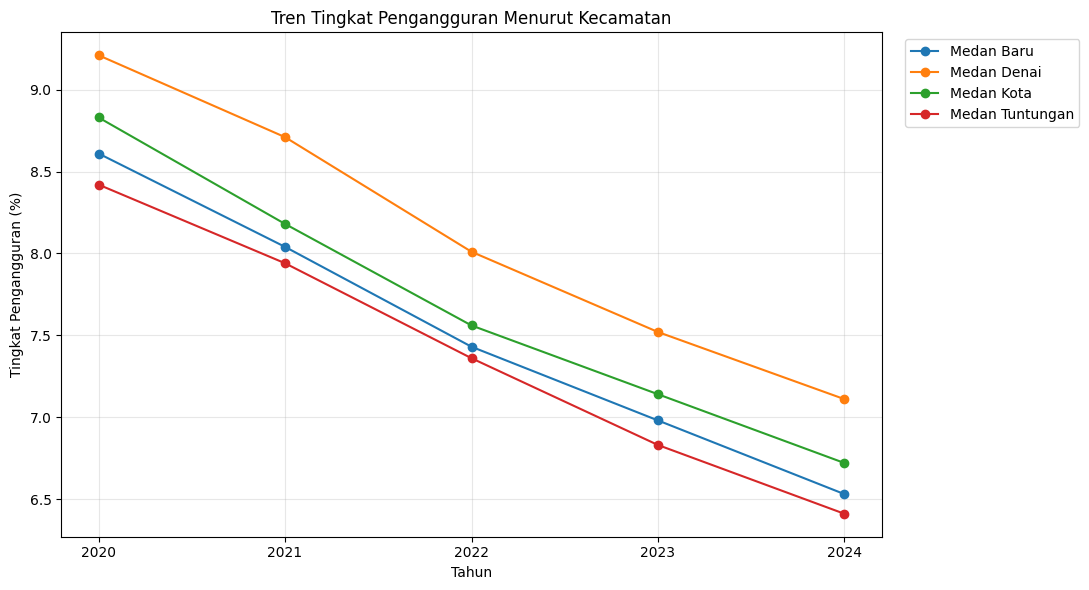

In [ ]:
# Tren tingkat pengangguran setiap kecamatan.
plt.figure(figsize=(11, 6))
for kecamatan, group in data.sort_values('Tahun').groupby('Kecamatan'):
    plt.plot(group['Tahun'], group[TARGET], marker='o', label=kecamatan)

plt.title('Tren Tingkat Pengangguran Menurut Kecamatan')
plt.xlabel('Tahun')
plt.ylabel('Tingkat Pengangguran (%)')
plt.xticks(sorted(data['Tahun'].unique()))
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

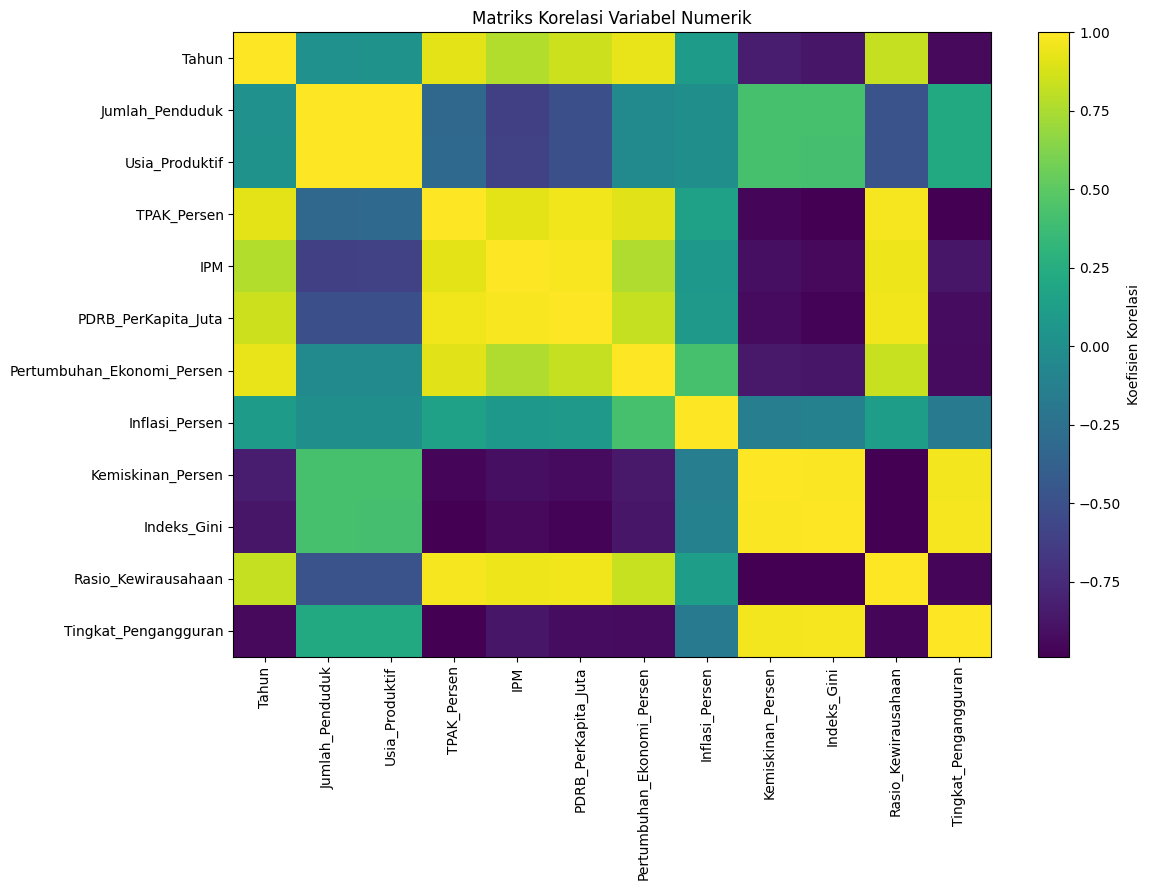

,Korelasi_dengan_Target
TPAK_Persen,-0.9848
Indeks_Gini,0.9765
Kemiskinan_Persen,0.9681
Rasio_Kewirausahaan,-0.9518
Tahun,-0.9360
Pertumbuhan_Ekonomi_Persen,-0.9331
PDRB_PerKapita_Juta,-0.9214
IPM,-0.8646
Jumlah_Penduduk,0.2226
Usia_Produktif,0.2185


In [ ]:
# Korelasi antarkolom numerik.
corr = data.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 9))
image = plt.imshow(corr, aspect='auto')
plt.colorbar(image, label='Koefisien Korelasi')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Matriks Korelasi Variabel Numerik')
plt.tight_layout()
plt.show()

display(
    corr[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .to_frame('Korelasi_dengan_Target')
)

## Tahap 7 — Menentukan fitur dan target

- **Target:** `Tingkat_Pengangguran`
- **Fitur kategorikal:** `Kecamatan`
- **Fitur numerik:** seluruh kolom selain target dan kecamatan.

In [ ]:
X = data.drop(columns=[TARGET])
y = data[TARGET]

categorical_features = ['Kecamatan']
numeric_features = [col for col in X.columns if col not in categorical_features]

print('Fitur numerik    :', numeric_features)
print('Fitur kategorikal:', categorical_features)
print('Target            :', TARGET)

Fitur numerik    : ['Tahun', 'Jumlah_Penduduk', 'Usia_Produktif', 'TPAK_Persen', 'IPM', 'PDRB_PerKapita_Juta', 'Pertumbuhan_Ekonomi_Persen', 'Inflasi_Persen', 'Kemiskinan_Persen', 'Indeks_Gini', 'Rasio_Kewirausahaan']
Fitur kategorikal: ['Kecamatan']
Target            : Tingkat_Pengangguran


## Tahap 8 — Pembagian data berbasis waktu

Tahun terakhir dijadikan data uji. Strategi ini lebih sesuai untuk simulasi prediksi masa mendatang daripada pembagian acak.

In [ ]:
TEST_YEAR = int(data['Tahun'].max())

train_mask = data['Tahun'] < TEST_YEAR
test_mask = data['Tahun'] == TEST_YEAR

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()
y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

if X_train.empty or X_test.empty:
    raise ValueError('Pembagian berbasis waktu gagal. Pastikan dataset memiliki sedikitnya dua tahun berbeda.')

print(f'Tahun pelatihan : {sorted(X_train["Tahun"].unique())}')
print(f'Tahun pengujian : {TEST_YEAR}')
print(f'Jumlah data latih: {len(X_train)}')
print(f'Jumlah data uji  : {len(X_test)}')

Tahun pelatihan : [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Tahun pengujian : 2024
Jumlah data latih: 16
Jumlah data uji  : 4


## Tahap 9 — Membangun pipeline praproses dan Random Forest awal

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('kategori', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numerik', 'passthrough', numeric_features),
    ],
    remainder='drop'
)

baseline_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

baseline_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', baseline_model),
    ]
)

baseline_pipeline.fit(X_train, y_train)
baseline_predictions = baseline_pipeline.predict(X_test)
print('Model awal berhasil dilatih.')

Model awal berhasil dilatih.


## Tahap 10 — Evaluasi model awal

In [ ]:
def regression_metrics(y_true, y_pred):
    """Menghasilkan metrik evaluasi regresi dalam bentuk dictionary."""
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': rmse,
        'R2': r2_score(y_true, y_pred),
        'MAPE_Persen': mean_absolute_percentage_error(y_true, y_pred) * 100,
    }

baseline_metrics = regression_metrics(y_test, baseline_predictions)
display(pd.DataFrame([baseline_metrics], index=['Random Forest Awal']).T)

,Random Forest Awal
MAE,0.4587
RMSE,0.4821
R2,-2.3051
MAPE_Persen,6.9481


In [ ]:
baseline_results = X_test[['Tahun', 'Kecamatan']].copy()
baseline_results['Aktual'] = y_test.values
baseline_results['Prediksi_Awal'] = baseline_predictions
baseline_results['Error'] = baseline_results['Aktual'] - baseline_results['Prediksi_Awal']
baseline_results['Absolute_Error'] = baseline_results['Error'].abs()
display(baseline_results.sort_values('Absolute_Error', ascending=False))

,Tahun,Kecamatan,Aktual,Prediksi_Awal,Error,Absolute_Error
19,2024,Medan Tuntungan,6.4100,7.0547,-0.6447,0.6447
16,2024,Medan Baru,6.5300,7.0806,-0.5506,0.5506
17,2024,Medan Kota,6.7200,7.0957,-0.3757,0.3757
18,2024,Medan Denai,7.1100,7.3739,-0.2639,0.2639


## Tahap 11 — Validasi silang berdasarkan kelompok tahun

Data dalam tahun yang sama ditempatkan dalam kelompok yang sama untuk mengurangi kebocoran informasi antartahun.

In [ ]:
train_groups = X_train['Tahun'].astype(str)
n_year_groups = train_groups.nunique()

if n_year_groups >= 3:
    cv_strategy = GroupKFold(n_splits=n_year_groups)
    cv_kwargs = {'groups': train_groups}
    print(f'Menggunakan GroupKFold dengan {n_year_groups} kelompok tahun.')
else:
    cv_strategy = KFold(n_splits=min(3, len(X_train)), shuffle=True, random_state=RANDOM_STATE)
    cv_kwargs = {}
    print('Jumlah kelompok tahun terbatas; menggunakan KFold.')

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}

cv_results = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False,
    **cv_kwargs,
)

cv_summary = pd.DataFrame({
    'MAE': -cv_results['test_MAE'],
    'RMSE': -cv_results['test_RMSE'],
    'R2': cv_results['test_R2'],
})
display(cv_summary)
display(cv_summary.agg(['mean', 'std']))

Menggunakan GroupKFold dengan 4 kelompok tahun.


,MAE,RMSE,R2
0,0.4845,0.5070,-2.8935
1,0.1231,0.1249,0.7562
2,0.1369,0.1564,0.7225
3,0.4551,0.4997,-1.8929


,MAE,RMSE,R2
mean,0.2999,0.3220,-0.8269
std,0.1966,0.2098,1.8542


## Tahap 12 — Optimasi hiperparameter dengan RandomizedSearchCV

In [ ]:
search_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
    ]
)

parameter_distributions = {
    'model__n_estimators': [100, 200, 300, 500, 700],
    'model__max_depth': [None, 3, 5, 7, 10],
    'model__min_samples_split': [2, 3, 4, 5],
    'model__min_samples_leaf': [1, 2, 3],
    'model__max_features': ['sqrt', 'log2', 0.7, 1.0],
    'model__bootstrap': [True, False],
}

random_search = RandomizedSearchCV(
    estimator=search_pipeline,
    param_distributions=parameter_distributions,
    n_iter=30,
    scoring='neg_mean_absolute_error',
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

if isinstance(cv_strategy, GroupKFold):
    random_search.fit(X_train, y_train, groups=train_groups)
else:
    random_search.fit(X_train, y_train)

print('Parameter terbaik:')
print(json.dumps(random_search.best_params_, indent=2))
print(f'MAE validasi terbaik: {-random_search.best_score_:.4f}')

Fitting 4 folds for each of 30 candidates, totalling 120 fits
Parameter terbaik:
{
  "model__n_estimators": 100,
  "model__min_samples_split": 3,
  "model__min_samples_leaf": 1,
  "model__max_features": 0.7,
  "model__max_depth": 3,
  "model__bootstrap": false
}
MAE validasi terbaik: 0.2448


## Tahap 13 — Evaluasi model terbaik pada tahun pengujian

In [ ]:
best_model = random_search.best_estimator_
best_predictions = best_model.predict(X_test)
best_metrics = regression_metrics(y_test, best_predictions)

metrics_comparison = pd.DataFrame(
    [baseline_metrics, best_metrics],
    index=['Model_Awal', 'Model_Terbaik']
)
display(metrics_comparison)

prediction_results = X_test[['Tahun', 'Kecamatan']].copy()
prediction_results['Aktual'] = y_test.values
prediction_results['Prediksi'] = best_predictions
prediction_results['Error'] = prediction_results['Aktual'] - prediction_results['Prediksi']
prediction_results['Absolute_Error'] = prediction_results['Error'].abs()
prediction_results['APE_Persen'] = (
    prediction_results['Absolute_Error'] / prediction_results['Aktual'].abs()
) * 100
display(prediction_results.sort_values('Absolute_Error', ascending=False))

,MAE,RMSE,R2,MAPE_Persen
Model_Awal,0.4587,0.4821,-2.3051,6.9481
Model_Terbaik,0.3989,0.4184,-1.4892,6.0382


,Tahun,Kecamatan,Aktual,Prediksi,Error,Absolute_Error,APE_Persen
19,2024,Medan Tuntungan,6.4100,6.9847,-0.5747,0.5747,8.9665
16,2024,Medan Baru,6.5300,6.9847,-0.4547,0.4547,6.9640
17,2024,Medan Kota,6.7200,7.0407,-0.3207,0.3207,4.7723
18,2024,Medan Denai,7.1100,7.3553,-0.2453,0.2453,3.4501


## Tahap 14 — Visualisasi aktual, prediksi, dan residual

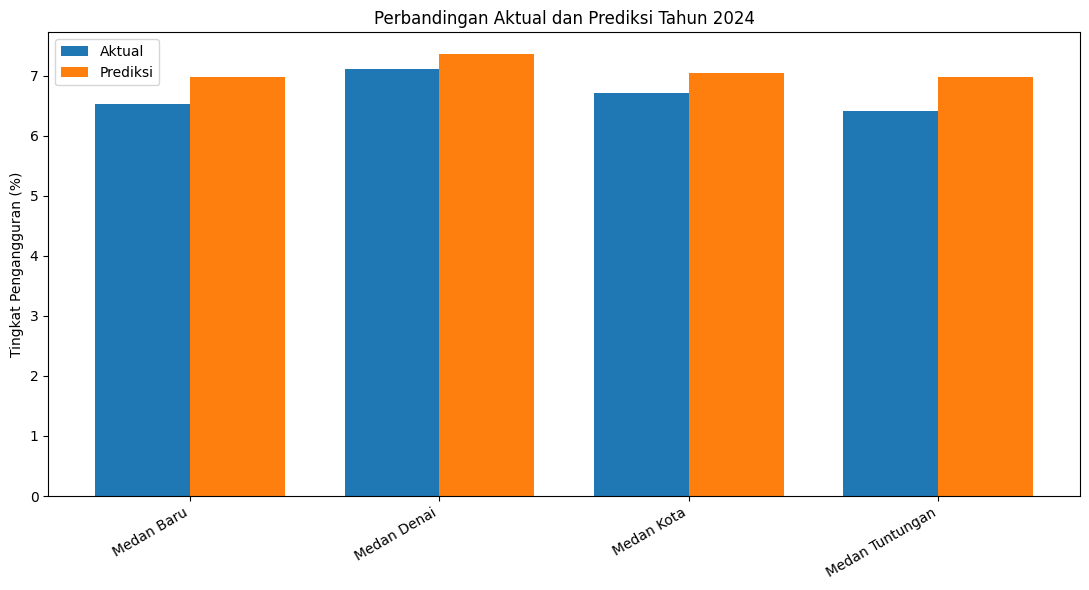

In [ ]:
plot_data = prediction_results.sort_values('Kecamatan')
x_positions = np.arange(len(plot_data))
bar_width = 0.38

plt.figure(figsize=(11, 6))
plt.bar(x_positions - bar_width / 2, plot_data['Aktual'], width=bar_width, label='Aktual')
plt.bar(x_positions + bar_width / 2, plot_data['Prediksi'], width=bar_width, label='Prediksi')
plt.xticks(x_positions, plot_data['Kecamatan'], rotation=30, ha='right')
plt.ylabel('Tingkat Pengangguran (%)')
plt.title(f'Perbandingan Aktual dan Prediksi Tahun {TEST_YEAR}')
plt.legend()
plt.tight_layout()
plt.show()

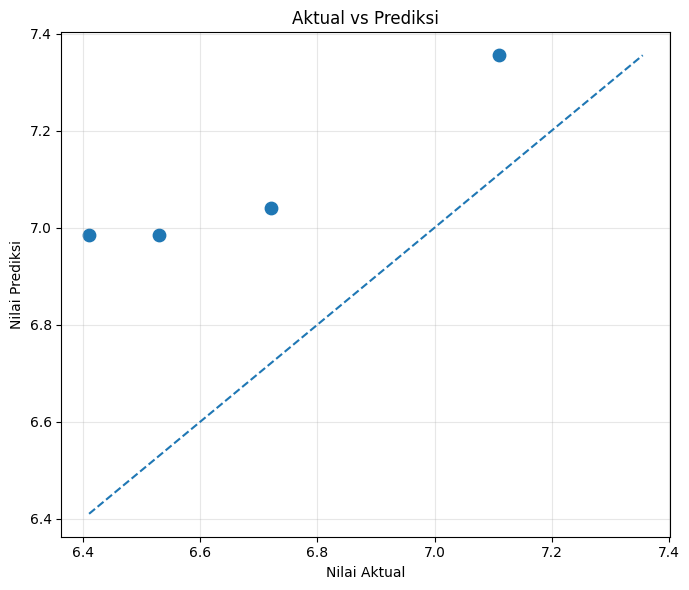

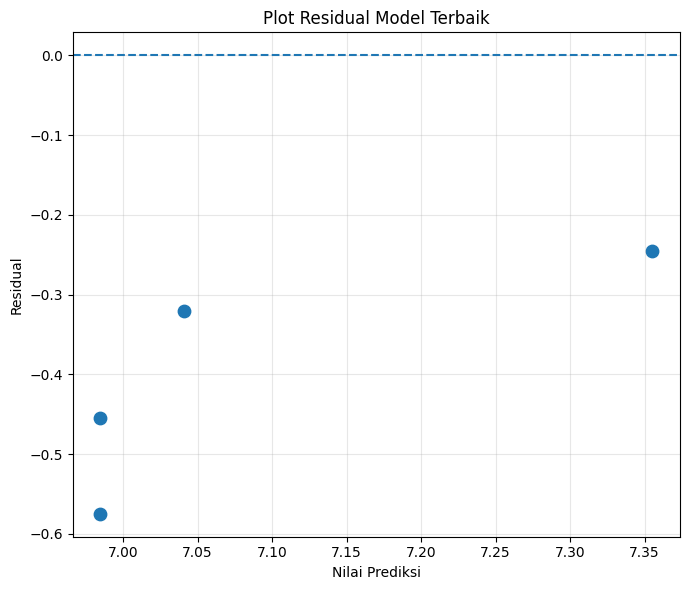

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, s=80)
minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle='--')
plt.xlabel('Nilai Aktual')
plt.ylabel('Nilai Prediksi')
plt.title('Aktual vs Prediksi')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.scatter(best_predictions, y_test - best_predictions, s=80)
plt.axhline(0, linestyle='--')
plt.xlabel('Nilai Prediksi')
plt.ylabel('Residual')
plt.title('Plot Residual Model Terbaik')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Tahap 15 — Analisis feature importance

,Fitur,Importance
7,TPAK_Persen,0.4669
10,Pertumbuhan_Ekonomi_Persen,0.3730
11,Inflasi_Persen,0.0528
13,Indeks_Gini,0.0332
12,Kemiskinan_Persen,0.0282
14,Rasio_Kewirausahaan,0.0175
4,Tahun,0.0156
8,IPM,0.0068
9,PDRB_PerKapita_Juta,0.0043
2,Kecamatan_Medan Kota,0.0017


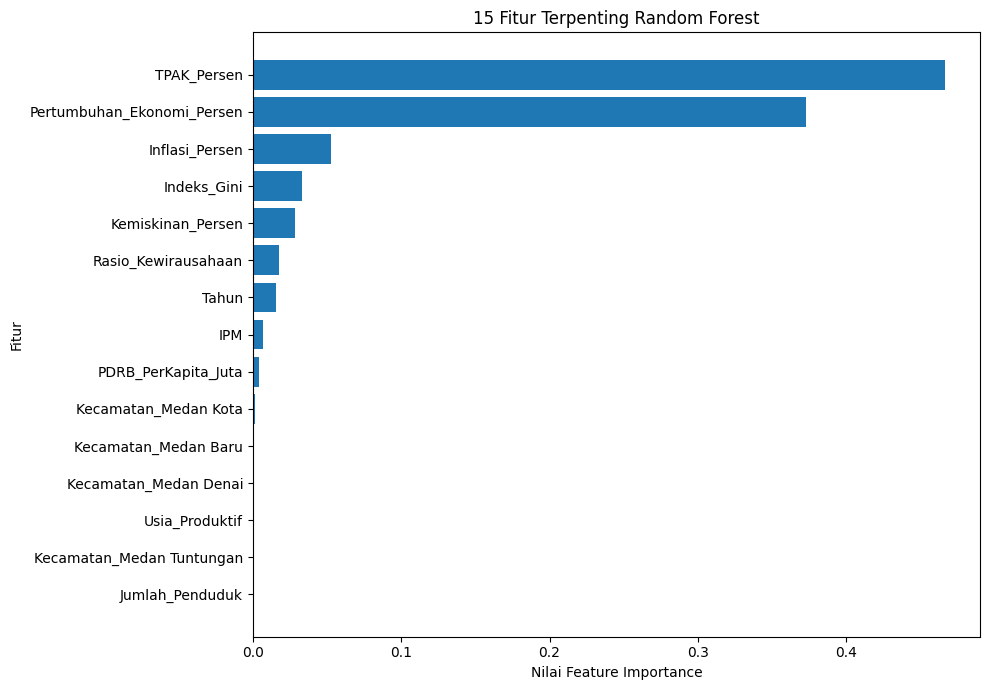

In [ ]:
fitted_preprocessor = best_model.named_steps['preprocessor']
fitted_rf = best_model.named_steps['model']

feature_names = fitted_preprocessor.get_feature_names_out()
feature_names = [
    name.replace('kategori__', '').replace('numerik__', '')
    for name in feature_names
]

importance_df = pd.DataFrame({
    'Fitur': feature_names,
    'Importance': fitted_rf.feature_importances_,
}).sort_values('Importance', ascending=False)

display(importance_df)

top_n = min(15, len(importance_df))
top_features = importance_df.head(top_n).sort_values('Importance')

plt.figure(figsize=(10, 7))
plt.barh(top_features['Fitur'], top_features['Importance'])
plt.xlabel('Nilai Feature Importance')
plt.ylabel('Fitur')
plt.title(f'{top_n} Fitur Terpenting Random Forest')
plt.tight_layout()
plt.show()

## Tahap 16 — Prediksi skenario kebijakan baru

Ubah nilai pada `scenario_data` sesuai skenario kebijakan yang akan diuji. Seluruh kolom prediktor wajib tersedia.

In [ ]:
# Contoh skenario tahun berikutnya berdasarkan satu kecamatan.
# Nilai berikut hanya contoh input simulasi dan perlu diganti dengan data resmi/proyeksi penelitian.
scenario_data = pd.DataFrame([
    {
        'Tahun': TEST_YEAR + 1,
        'Kecamatan': 'Medan Baru',
        'Jumlah_Penduduk': 44600,
        'Usia_Produktif': 30200,
        'TPAK_Persen': 72.0,
        'IPM': 84.5,
        'PDRB_PerKapita_Juta': 95.0,
        'Pertumbuhan_Ekonomi_Persen': 5.60,
        'Inflasi_Persen': 2.30,
        'Kemiskinan_Persen': 6.30,
        'Indeks_Gini': 0.318,
        'Rasio_Kewirausahaan': 3.10,
    }
])

scenario_prediction = best_model.predict(scenario_data)[0]
scenario_output = scenario_data[['Tahun', 'Kecamatan']].copy()
scenario_output['Prediksi_Tingkat_Pengangguran'] = scenario_prediction
display(scenario_output)

,Tahun,Kecamatan,Prediksi_Tingkat_Pengangguran
0,2025,Medan Baru,6.9847


## Tahap 17 — Menyimpan model, hasil prediksi, dan metrik

In [ ]:
OUTPUT_DIR = 'hasil_random_forest_pengangguran'
os.makedirs(OUTPUT_DIR, exist_ok=True)

model_path = os.path.join(OUTPUT_DIR, 'model_random_forest_pengangguran.joblib')
prediction_path = os.path.join(OUTPUT_DIR, 'hasil_prediksi_tahun_uji.csv')
importance_path = os.path.join(OUTPUT_DIR, 'feature_importance.csv')
clean_data_path = os.path.join(OUTPUT_DIR, 'dataset_bersih.csv')
metrics_path = os.path.join(OUTPUT_DIR, 'metrik_evaluasi.csv')
scenario_path = os.path.join(OUTPUT_DIR, 'hasil_prediksi_skenario.csv')

joblib.dump(best_model, model_path)
prediction_results.to_csv(prediction_path, index=False)
importance_df.to_csv(importance_path, index=False)
data.to_csv(clean_data_path, index=False)
metrics_comparison.to_csv(metrics_path)
scenario_output.to_csv(scenario_path, index=False)

zip_path = 'hasil_random_forest_pengangguran.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for filename in os.listdir(OUTPUT_DIR):
        full_path = os.path.join(OUTPUT_DIR, filename)
        archive.write(full_path, arcname=filename)

print('Berkas berhasil disimpan:')
for filename in os.listdir(OUTPUT_DIR):
    print('-', filename)

files.download(zip_path)

Berkas berhasil disimpan:
- hasil_prediksi_skenario.csv
- metrik_evaluasi.csv
- hasil_prediksi_tahun_uji.csv
- feature_importance.csv
- dataset_bersih.csv
- model_random_forest_pengangguran.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Tahap 18 — Pedoman interpretasi hasil

1. **MAE** menunjukkan rata-rata selisih absolut antara nilai aktual dan prediksi. Semakin kecil semakin baik.
2. **RMSE** memberi penalti lebih besar terhadap kesalahan prediksi yang ekstrem. Semakin kecil semakin baik.
3. **R²** menunjukkan proporsi variasi target yang dijelaskan model. Nilai dapat negatif pada data uji yang sangat kecil atau ketika model lebih buruk daripada prediksi rata-rata.
4. **MAPE** menunjukkan rata-rata kesalahan relatif dalam persen. Semakin kecil semakin baik.
5. **Feature importance** menunjukkan kontribusi relatif fitur di dalam Random Forest, tetapi tidak membuktikan hubungan sebab-akibat.
6. Untuk rekomendasi kebijakan, gabungkan hasil model dengan analisis ekonomi tenaga kerja, validasi data resmi, dan kajian per kecamatan.